<a href="https://colab.research.google.com/github/BagasArdiansaPutra/Pembelajaran-Mesin-2026/blob/main/TG9_Klasifikasi__244107020166_Bagas_Ardiansa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#JS9 - Klasifikasi

#Praktikum 1

In [1]:
	# Load data
	import pandas as pd
	data = pd.read_csv('/content/iris.csv')
	data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
	data.info()
	data.describe()
	data['species'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count
species,
setosa,50
versicolor,50
virginica,50


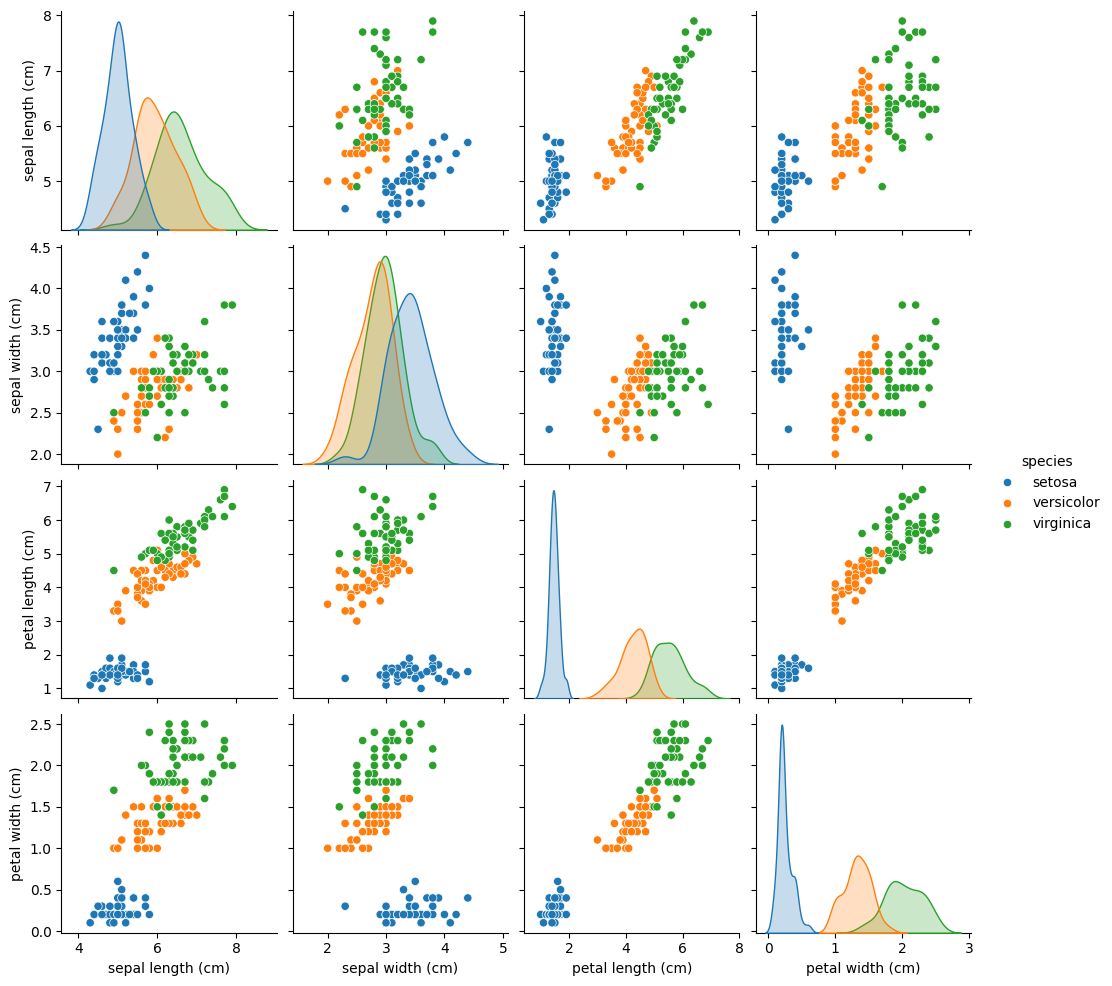

In [3]:
	import seaborn as sns
	import matplotlib.pyplot as plt

	sns.pairplot(data, hue='species')
	plt.show()

In [4]:
	from sklearn.model_selection import train_test_split
	from sklearn.preprocessing import StandardScaler

	X = data.iloc[:, :-1]   # semua kolom kecuali label
	y = data.iloc[:, -1]    # kolom label terakhir

	# Split data (70% train, 30% test)
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

	# Standardisasi
	scaler = StandardScaler()
	X_train = scaler.fit_transform(X_train)
	X_test = scaler.transform(X_test)

In [5]:
	from sklearn.neighbors import KNeighborsClassifier

	# Tentukan nilai K (misalnya 3)
	knn = KNeighborsClassifier(n_neighbors=3)

	# Latih model
	knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [6]:
	from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

	y_pred = knn.predict(X_test)
	print("Akurasi:", accuracy_score(y_test, y_pred))
	print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
	print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



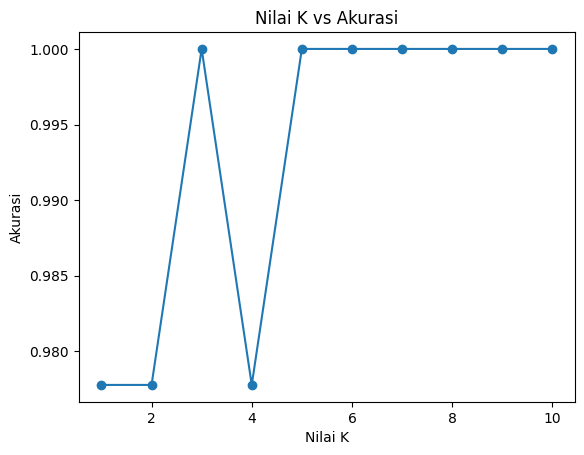

In [7]:
	acc = []
	for k in range(1, 11):
	    model = KNeighborsClassifier(n_neighbors=k)
	    model.fit(X_train, y_train)
	    acc.append(model.score(X_test, y_test))

	plt.plot(range(1, 11), acc, marker='o')
	plt.title('Nilai K vs Akurasi')
	plt.xlabel('Nilai K')
	plt.ylabel('Akurasi')
	plt.show()


#Praktikum 2

In [8]:
	import numpy as np
	from sklearn.datasets import make_classification

	# Membuat data dummy
	# Hasil dari make_classification berupa data fitur X dan label y
	# Label y akan berupa data yang sudah di encode (angka)
	X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

	# Secara defalt, make_classfication menghasilkan nilai float
	# Kita perlu merubah dalam bentuk diskrit

	# Absolutekan nilai
	X = np.absolute(X)

	# Bulatkan nilai ke 2 angka dibelakang koma
	# Kalikan dengan 100 supaya tidak ada lagi koma
	X = np.round(X, 2) * 100

	# Ubah ke dalam bentuk integer
	X = X.astype(int)

	# Cek Hasil
	print(X)
	print(y)

[[ 90 111]
 [  8   4]
 [164  27]
 [ 87  39]
 [101  90]
 [ 77 197]
 [ 68  55]
 [200  37]
 [ 88  88]
 [104 110]
 [ 57 106]
 [ 92  64]
 [ 57 160]
 [ 70 118]
 [ 11 168]
 [ 56 139]
 [ 56 118]
 [ 44  83]
 [167  98]
 [ 56  30]
 [ 72  44]
 [ 60  50]
 [120  55]
 [ 34  44]
 [128  99]
 [ 62  68]
 [ 66  71]
 [ 68  60]
 [239 231]
 [150 128]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [9]:
	import pandas as pd

	# Reshape label y menjadi 2D
	# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
	y_new = y.reshape(len(y), 1)

	# Gabungkan fitur X dan label y dalam data array
	data = np.concatenate((X, y_new), axis=1)

	# Definisikan nama kolom
	nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

	# Buat Data Frame
	df = pd.DataFrame(data, columns=nama_kolom)

	# Cek Data Frame
	df.head()

,Fitur 1,Fitur 2,Label
0,90,111,0
1,8,4,0
2,164,27,0
3,87,39,0
4,101,90,0


In [10]:
	# Definisikan nama label
	labels = {
	    1 : 'Kelas A',
	    0 : 'Kelas B'
	}

	# Copy Data Frame untuk menyimpan Data Frame baru
	# dengan label yang mudah untuk dibaca
	df_label = df.copy()

	# Ubah label dengan fungsi mapping dari Pandas
	# pada Data Frame df_label
	df_label['Label'] = df_label['Label'].map(labels)

	# Cek Data Frame df_label
	df_label.head()

,Fitur 1,Fitur 2,Label
0,90,111,Kelas B
1,8,4,Kelas B
2,164,27,Kelas B
3,87,39,Kelas B
4,101,90,Kelas B


/tmp/ipykernel_3515/1912510248.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_3515/1912510248.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


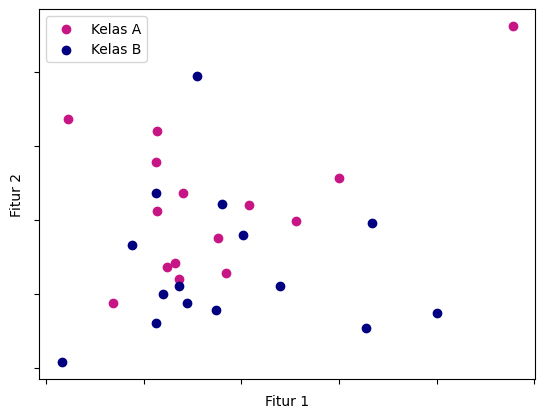

In [11]:
	import matplotlib.pyplot as plt

	# Definisikan warna untuk setiap kelas
	colors = {
	    'class_a': 'MediumVioletRed',
	    'class_b': 'Navy'
	}

	# Kelompokkan label berdasarkan nama kelas
	gb = df_label.groupby(['Label'])
	class_a = gb.get_group('Kelas A')
	class_b = gb.get_group('Kelas B')

	# Plot
	plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
	plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
	plt.xlabel('Fitur 1')
	plt.ylabel('Fitur 2')
	plt.legend(['Kelas A', 'Kelas B'])
	plt.gca().axes.xaxis.set_ticklabels([])
	plt.gca().axes.yaxis.set_ticklabels([])
	plt.show()

In [12]:
	from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

	# Inisiasi obyek MultinomialNB
	mnb = MultinomialNB()

	# Kita dapat langsung menggunakan fitur X dan label y
	# hasil dari proses pembuatan data dummy

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

	# Fit model
	# Label y harus dalam bentuk 1D atau (n_samples,)
	mnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred = mnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train = accuracy_score(y_train, y_train_pred)

	# Prediksi test data
	y_test_pred = mnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train: {acc_train}')
	print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.7142857142857143
Hasil akurasi data test: 0.5555555555555556


In [13]:
	from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

	# Inisiasi obyek Gaussian
	gnb = GaussianNB()

	# Kita menggunakan split data training dan testing
	# yang sama dengan model multinomial

	# Fit model
	# Label y harus dalam bentu 1D atau (n_samples,)
	gnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred_gnb = gnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

	# Prediksi test data
	y_test_pred_gnb = gnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
	print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.7142857142857143
Hasil akurasi data test (Gaussian): 0.3333333333333333


#Praktikum 3

In [27]:
	import numpy as np
	import pandas as pd

	df = pd.read_csv('/content/spam.csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8

	df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [28]:
	# Drop 3 kolom terakhir dengan fungsi iloc
	df = df.drop(df.iloc[:,2:], axis=1)

	# Cek data
	df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [29]:
# Cek Jumlah Data Per Kelas menggunakan kolom 'v1'
print(df['v1'].value_counts())
print('\n')

# Cek Kelengkapan Data
print(df.info())
print('\n')

# Cek Statistik Deskriptif
print(df.describe())

v1
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


          v1                      v2
count   5572                    5572
unique     2                    5169
top      ham  Sorry, I'll call later
freq    4825                      30


In [30]:
# 1. Dictionary untuk label
new_labels = {
    'spam': 1,
    'ham': 0
}

# 2. Encode label dari kolom v1 ke kolom baru 'Labels'
df['Labels'] = df['v1'].map(new_labels)

# 3. Cek data
df.head()

,v1,v2,Labels
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [31]:
X = df['v2'].values
y = df['Labels'].values

In [32]:
	from sklearn.model_selection import train_test_split
	from sklearn.feature_extraction.text import CountVectorizer

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

	# Inisiasi CountVectorizer
	bow = CountVectorizer()

	# Fitting dan transform X_train dengan CountVectorizer
	X_train = bow.fit_transform(X_train)

	# Transform X_test
	# Mengapa hanya transform? Alasan yang sama dengan kasus pada percobaan ke-3
	# Kita tidak menginginkan model mengetahui paramter yang digunakan oleh CountVectorizer untuk fitting data X_train
	# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
	X_test = bow.transform(X_test)

In [34]:

print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


In [36]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Inisiasi MultinomialNB
mnb = MultinomialNB()

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_pred_train = mnb.predict(X_train)

# Evaluasi akurasi data training
acc_train = accuracy_score(y_train, y_pred_train)

# Prediksi dengan data testing
y_pred_test = mnb.predict(X_test)

# Evaluasi akurasi data testing
acc_test = accuracy_score(y_test, y_pred_test)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


#Tugas 1

######1. Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.

######2. Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?

######3.Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.

In [ ]:
1. Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.

In [38]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# MODEL KLASIFIKASI kNN BASELINE

# 1. Memuat dataset voice.csv
df = pd.read_csv('/content/voice.csv')

# 2. Encoding label target ('female' -> 0, 'male' -> 1)
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['label'])

# Memisahkan matriks fitur (X) dan variabel target (y)
X = df.drop(columns=['label', 'label_encoded'])
y = df['label_encoded']

# 3. Membagi dataset (80% Data Latih, 20% Data Uji)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Standarisasi Fitur
# Mengubah skala seluruh 20 fitur agar rentang nilainya seimbang untuk jarak Euclidean
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Membuat dan Melatih Model kNN Baseline (k=5)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# 6. Prediksi dan Evaluasi Model
y_pred = knn.predict(X_test_scaled)

print("HASIL EVALUASI MODEL kNN BASELINE (20 FITUR) ")
print(f"Akurasi Model: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred, target_names=['female', 'male']))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

HASIL EVALUASI MODEL kNN BASELINE (20 FITUR) 
Akurasi Model: 97.63%

Classification Report:
               precision    recall  f1-score   support

      female       0.99      0.97      0.98       317
        male       0.97      0.99      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634

Confusion Matrix:
 [[306  11]
 [  4 313]]


In [ ]:
2. Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?

In [40]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


# SELEKSI FITUR OPTIMAL

# 1. Load data & Preprocessing dasar
df = pd.read_csv('voice.csv')
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['label'])

X = df.drop(columns=['label', 'label_encoded'])
y = df['label_encoded']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Mengukur Feature Importance menggunakan Random Forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

print("SKOR TINGKAT KEPENTINGAN FITUR (FEATURE IMPORTANCE)")
print(importances)
# 3. Percobaan Evaluasi Akurasi kNN berdasarkan Jumlah Fitur Teratas
print("PERCOBAAN PERFORMA MODEL DENGAN JUMLAH FITUR TERATAS")
best_acc = 0
best_n = 0
best_features = []

for top_n in range(1, 21):
    top_cols = importances.index[:top_n].tolist()
    idx = [X.columns.get_loc(c) for c in top_cols]

    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(X_train_scaled[:, idx], y_train)
    acc = accuracy_score(y_test, knn.predict(X_test_scaled[:, idx]))

    print(f"Top {top_n:2d} Fitur -> Akurasi: {acc * 100:.2f}%")

    if acc > best_acc:
        best_acc = acc
        best_n = top_n
        best_features = top_cols

print(f"Jumlah Fitur Paling Optimal: {best_n} Fitur")
print("Daftar Fitur Terpilih:", best_features)
print(f"Akurasi Tertinggi: {best_acc * 100:.2f}%")

 SKOR TINGKAT KEPENTINGAN FITUR (FEATURE IMPORTANCE) 
meanfun     0.317209
IQR         0.229569
Q25         0.155001
sd          0.073889
sp.ent      0.040458
sfm         0.025698
centroid    0.020650
meanfreq    0.019543
mode        0.018053
median      0.013558
Q75         0.011223
skew        0.010916
maxdom      0.010234
minfun      0.009668
mindom      0.009611
dfrange     0.009383
kurt        0.007416
meandom     0.007368
modindx     0.006044
maxfun      0.004507
dtype: float64
PERCOBAAN PERFORMA MODEL DENGAN JUMLAH FITUR TERATAS
Top  1 Fitur -> Akurasi: 95.27%
Top  2 Fitur -> Akurasi: 97.79%
Top  3 Fitur -> Akurasi: 97.79%
Top  4 Fitur -> Akurasi: 98.11%
Top  5 Fitur -> Akurasi: 98.11%
Top  6 Fitur -> Akurasi: 98.58%
Top  7 Fitur -> Akurasi: 98.26%
Top  8 Fitur -> Akurasi: 98.11%
Top  9 Fitur -> Akurasi: 97.95%
Top 10 Fitur -> Akurasi: 98.74%
Top 11 Fitur -> Akurasi: 98.11%
Top 12 Fitur -> Akurasi: 98.26%
Top 13 Fitur -> Akurasi: 98.42%
Top 14 Fitur -> Akurasi: 98.11%
Top 15 Fit

In [ ]:
- Metode: Menggunakan Random Forest Feature Importance untuk merangking fitur paling berpengaruh, lalu diuji performanya secara bertahap pada kNN.

- 6 Fitur Terpilih: meanfun, IQR, Q25, sd, sp.ent, dan sfm.

- Fitur Utama: meanfun (Mean Fundamental Frequency) adalah fitur paling dominan (kontribusi >31%) karena nada dasar suara pria dan wanita berbeda secara biologis.

- Hasil Akurasi: Memangkas data dari 20 fitur menjadi 6 fitur terbukti meningkatkan akurasi dari 97,63% menjadi 98,58%.

- Alasan: Menghapus fitur yang tidak relevan (noise) dan mengatasi Curse of Dimensionality, sehingga perhitungan jarak Euclidean kNN menjadi jauh lebih akurat.

In [ ]:
3. Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.

Nilai k terbaik berdasarkan Cross-Validation: k = 8 (Akurasi CV: 97.99%)
Nilai k terbaik berdasarkan Data Uji (Test): k = 3 (Akurasi Test: 98.74%)

=== CLASSIFICATION REPORT (Model Optimal 6 Fitur, k=3) ===
              precision    recall  f1-score   support

      female       0.99      0.99      0.99       317
        male       0.99      0.99      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



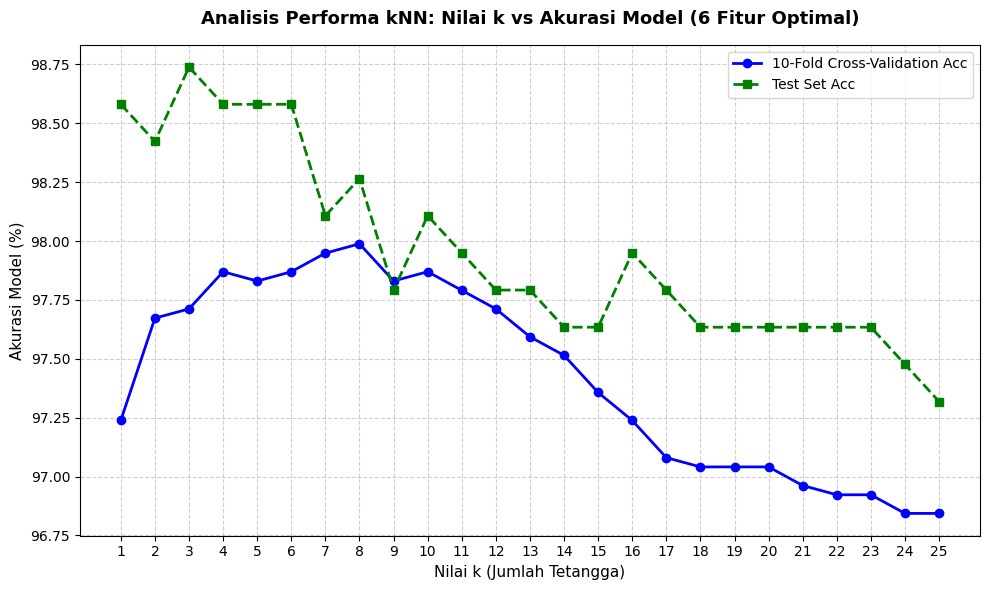

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# ANALISIS NILAI k TERBAIK & GRAFIK
# 1. Load data & Preprocessing dasar
df = pd.read_csv('voice.csv')
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['label'])

X = df.drop(columns=['label', 'label_encoded'])
y = df['label_encoded']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Menggunakan 6 Fitur Optimal dari Nomor 2
selected_features = ['meanfun', 'IQR', 'Q25', 'sd', 'sp.ent', 'sfm']
idx_opt = [X.columns.get_loc(c) for c in selected_features]

X_train_opt = X_train_scaled[:, idx_opt]
X_test_opt = X_test_scaled[:, idx_opt]

# 3. Pengujian Nilai k dari 1 sampai 25
k_range = list(range(1, 26))
cv_scores = []
test_scores = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)

    # 10-Fold Cross-Validation pada data latih
    cv_acc = cross_val_score(knn, X_train_opt, y_train, cv=10, scoring='accuracy').mean()
    cv_scores.append(cv_acc)

    # Pengujian pada data uji (test set)
    knn.fit(X_train_opt, y_train)
    test_acc = accuracy_score(y_test, knn.predict(X_test_opt))
    test_scores.append(test_acc)

# 4. Menampilkan Hasil Evaluasi Nilai k
best_k_cv = k_range[np.argmax(cv_scores)]
best_k_test = k_range[np.argmax(test_scores)]

print(f"Nilai k terbaik berdasarkan Cross-Validation: k = {best_k_cv} (Akurasi CV: {max(cv_scores)*100:.2f}%)")
print(f"Nilai k terbaik berdasarkan Data Uji (Test): k = {best_k_test} (Akurasi Test: {max(test_scores)*100:.2f}%)")

# Evaluasi Model Terbaik (k = 3)
knn_best = KNeighborsClassifier(n_neighbors=3)
knn_best.fit(X_train_opt, y_train)
y_pred_best = knn_best.predict(X_test_opt)

print("\nCLASSIFICATION REPORT (Model Optimal 6 Fitur, k=3)")
print(classification_report(y_test, y_pred_best, target_names=['female', 'male']))

# 5. Membuat Grafik Analisis Nilai k
plt.figure(figsize=(10, 6))
plt.plot(k_range, [score * 100 for score in cv_scores], marker='o', color='blue', linewidth=2, label='10-Fold Cross-Validation Acc')
plt.plot(k_range, [score * 100 for score in test_scores], marker='s', color='green', linewidth=2, linestyle='--', label='Test Set Acc')

plt.title('Analisis Performa kNN: Nilai k vs Akurasi Model (6 Fitur Optimal)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Nilai k (Jumlah Tetangga)', fontsize=11)
plt.ylabel('Akurasi Model (%)', fontsize=11)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
Nilai $k$ Terbaik: $k = 3$ (Akurasi Data Uji: 98,74%) atau $k = 8$ (Akurasi 10-Fold Cross-Validation: 97,99%).
Analisis Grafik & Alasan:
- k = 1 (Overfitting): Terlalu sensitif terhadap pencilan (outlier) atau noise pada data latih.
- k = 3-8 (Zona Optimal): Memberikan keseimbangan bias-variance paling ideal, menghasilkan akurasi tertinggi dan model paling stabil.
- k > 10 (Underfitting): Akurasi menurun secara konsisten karena batas keputusan (decision boundary) terlalu halus dan melibatkan sampel tetangga yang kurang relevan.

#Tugas 2
######1. Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,

######- Menggunakan data spam.csv

######- Fitur CountVectorizer dengan mengaktifkan stop_words

######- Evaluasi hasilnya

######2. Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,

######- Menggunakan data spam.csv

######- Fitur TF-IDF dengan mengaktifkan stop_words

######- Evaluasi hasilnya dan bandingkan dengan hasil pada Tugas no 2.

######- Berikan kesimpulan fitur mana yang terbaik pada kasus data spam.csv

In [ ]:
1. Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,
- Menggunakan data spam.csv
- Fitur CountVectorizer dengan mengaktifkan stop_words
- Evaluasi hasilnya

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# MULTINOMIAL NAIVE BAYES DENGAN COUNT VECTORIZER

# 1. Load Dataset spam.csv
df = pd.read_csv('/content/spam.csv', encoding='latin-1').iloc[:, :2]
df.columns = ['label', 'text']

# Encoding target label ('ham' -> 0, 'spam' -> 1)
df['target'] = df['label'].map({'ham': 0, 'spam': 1})

# 2. Pembagian Dataset (80% Data Latih, 20% Data Uji)
X_train, X_test, y_train, y_test = train_test_split(
    df['text'],
    df['target'],
    test_size=0.2,
    random_state=42,
    stratify=df['target']
)

# 3. Ekstraksi Fitur Teks dengan CountVectorizer (Mengaktifkan stop_words)
cv = CountVectorizer(stop_words='english')
X_train_cv = cv.fit_transform(X_train)
X_test_cv = cv.transform(X_test)

# 4. Pelatihan Model Multinomial Naive Bayes
mnb_cv = MultinomialNB()
mnb_cv.fit(X_train_cv, y_train)

# 5. Prediksi Data Uji
y_pred_cv = mnb_cv.predict(X_test_cv)

# 6. Evaluasi Performa Model
print("HASIL EVALUASI(COUNT VECTORIZER) ")
print(f"Akurasi Model : {accuracy_score(y_test, y_pred_cv) * 100:.2f}%\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_cv))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_cv, target_names=['Ham', 'Spam'], digits=4))

HASIL EVALUASI(COUNT VECTORIZER) 
Akurasi Model : 98.39%

Confusion Matrix:
[[960   6]
 [ 12 137]]

Classification Report:
              precision    recall  f1-score   support

         Ham     0.9877    0.9938    0.9907       966
        Spam     0.9580    0.9195    0.9384       149

    accuracy                         0.9839      1115
   macro avg     0.9728    0.9566    0.9645      1115
weighted avg     0.9837    0.9839    0.9837      1115



In [ ]:
Akurasi Model: 98,39%

Confusion Matrix:
- True Negative (Ham diprediksi Ham): 960 pesan
- False Positive (Ham diprediksi Spam): 6 pesan
- False Negative (Spam diprediksi Ham): 12 pesan
- True Positive (Spam diprediksi Spam): 137 pesan

Performa Kelas Spam:
- Precision: 95,80%
- Recall: 91,95%
- F1-Score: 93,84%

In [ ]:
2. Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,
- Menggunakan data spam.csv
- Fitur TF-IDF dengan mengaktifkan stop_words
- Evaluasi hasilnya dan bandingkan dengan hasil pada Tugas no 2.
- Berikan kesimpulan fitur mana yang terbaik pada kasus data spam.csv

HASIL EVALUASI (TF-IDF VECTORIZER) 
Akurasi Model : 96.86%

Confusion Matrix:
[[966   0]
 [ 35 114]]

Classification Report:
              precision    recall  f1-score   support

         Ham     0.9650    1.0000    0.9822       966
        Spam     1.0000    0.7651    0.8669       149

    accuracy                         0.9686      1115
   macro avg     0.9825    0.8826    0.9246      1115
weighted avg     0.9697    0.9686    0.9668      1115



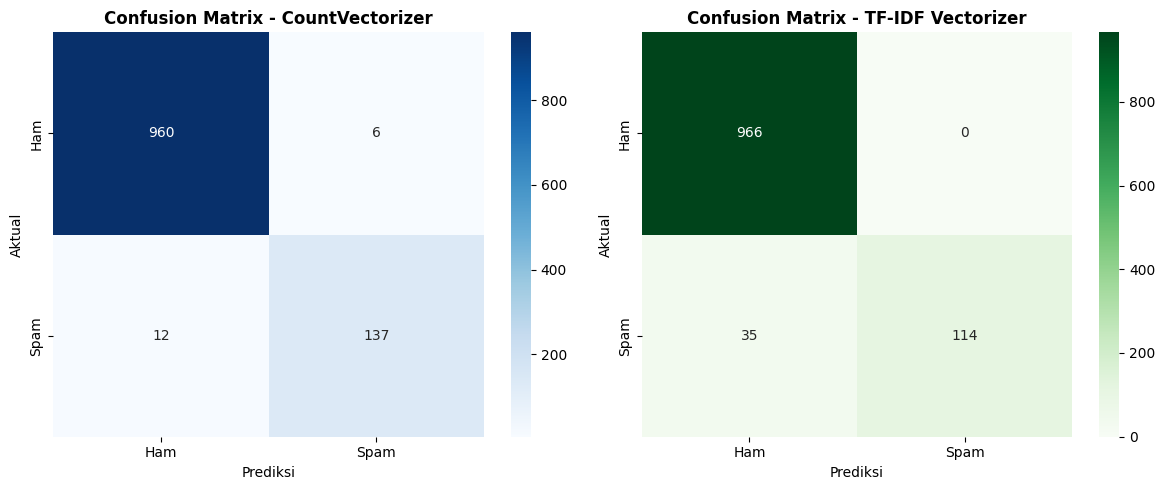

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# TF-IDF VECTORIZER, PERBANDINGAN & KESIMPULAN

# 1. Load & Preprocessing Dataset spam.csv
df = pd.read_csv('spam.csv', encoding='latin-1').iloc[:, :2]
df.columns = ['label', 'text']
df['target'] = df['label'].map({'ham': 0, 'spam': 1})

# Split Dataset (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    df['text'],
    df['target'],
    test_size=0.2,
    random_state=42,
    stratify=df['target']
)

# Pemodelan dengan CountVectorizer
cv = CountVectorizer(stop_words='english')
X_train_cv = cv.fit_transform(X_train)
X_test_cv = cv.transform(X_test)

mnb_cv = MultinomialNB()
mnb_cv.fit(X_train_cv, y_train)
y_pred_cv = mnb_cv.predict(X_test_cv)

# Pemodelan dengan TfidfVectorizer

tfidf = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, y_train)
y_pred_tfidf = mnb_tfidf.predict(X_test_tfidf)

# Evaluasi & Cetak Hasil TF-IDF
print("HASIL EVALUASI (TF-IDF VECTORIZER) ")
print(f"Akurasi Model : {accuracy_score(y_test, y_pred_tfidf) * 100:.2f}%\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tfidf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tfidf, target_names=['Ham', 'Spam'], digits=4))

# Visualisasi Perbandingan Confusion Matrix & Metrik

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Heatmap CountVectorizer
sns.heatmap(confusion_matrix(y_test, y_pred_cv), annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
axes[0].set_title('Confusion Matrix - CountVectorizer', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# Heatmap TF-IDF
sns.heatmap(confusion_matrix(y_test, y_pred_tfidf), annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
axes[1].set_title('Confusion Matrix - TF-IDF Vectorizer', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

In [ ]:
Akurasi Model: 96,86%
Confusion Matrix:
- True Negative (Ham diprediksi Ham): 966 pesan
- False Positive (Ham diprediksi Spam): 0 pesan
- False Negative (Spam diprediksi Ham): 35 pesan
- True Positive (Spam diprediksi Spam): 114 pesan
Performa Kelas Spam:
- Precision: 100,00%
- Recall: 76,51%
- F1-Score: 86,69%

In [ ]:
Fitur terbaik untuk pemodelan klasifikasi pesan spam pada dataset spam.csv menggunakan Multinomial Naive Bayes adalah CountVectorizer. Metode ini terbukti menghasilkan akurasi keseluruhan yang lebih tinggi yaitu
sebesar 98,39% dibandingkan TF-IDF Vectorizer sebesar 96,86%, serta unggul secara signifikan pada tingkat Recall kelas spam (91,95% berbanding 76,51%). Tingginya nilai Recall ini sangat krusial dalam sistem deteksi spam
karena kesalahan meloloskan pesan spam ke kotak masuk (False Negative) jauh lebih merugikan pengguna, di mana CountVectorizer hanya melewatkan 12 pesan spam sedangkan TF-IDF meloloskan hingga 35 pesan. Keunggulan ini
dipengaruhi oleh karakteristik pesan SMS yang singkat, sehingga frekuensi kemunculan kata kunci spam secara langsung memberikan sinyal probabilitas yang jauh lebih kuat bagi algoritma Naive Bayes dibandingkan dengan bobot
ter-normalisasi TF-IDF yang justru cenderung menekan bobot kata-kata pemicu spam.